# 08 価格改定・席レイアウト変更の前後比較

全店舗のログから、2024年4月の価格改定と、過去の席レイアウト変更前後の実績を比較する。各期間は変更日の前28日と変更日から28日で、曜日構成を揃える。

**これは因果推論ではない。** 季節、天候、祝日、メニュー、キャンペーン、他の変更や販売制限が同時に変化する。日々の売上・来店・数量は2024年までの実績であり、将来同日の特徴量には使わない。

In [1]:
from pathlib import Path
import zipfile,io
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input'; sns.set_theme(style='whitegrid'); pd.options.display.float_format='{:,.4f}'.format
stores=pd.read_csv(INPUT/'stores.csv'); menus=pd.read_csv(INPUT/'menus.csv'); seats=pd.read_csv(INPUT/'seat_layout.csv',parse_dates=['effective_start_date','effective_end_date'])
all_stores=stores.store_id.tolist(); events=[]
for sid,group in seats.sort_values('effective_start_date').groupby('store_id'):
    prev=None
    for _,row in group.iterrows():
        if prev is not None and row.layout_version!=prev.layout_version:
            events.append({'store_id':sid,'date':row.effective_start_date,'before_version':prev.layout_version,'after_version':row.layout_version,'before_seats':prev.total_seats,'after_seats':row.total_seats})
        prev=row
events=pd.DataFrame(events)
events=events[(events.date-pd.Timedelta(days=28)>=pd.Timestamp('2022-01-01')) & (events.date+pd.Timedelta(days=27)<=pd.Timestamp('2024-12-31'))].copy()
display(events.sort_values(['date','store_id']))

,store_id,date,before_version,after_version,before_seats,after_seats
0,S001,2023-04-15,L01,L02,90,108
4,S003,2023-05-15,L01,L02,90,90
10,S007,2023-07-15,L01,L02,90,90
14,S010,2023-08-15,L01,L02,90,108
2,S002,2023-09-15,L01,L02,90,90
13,S009,2023-10-15,L01,L02,90,108
6,S004,2023-11-15,L01,L02,90,108
8,S005,2024-02-15,L01,L02,90,90
12,S008,2024-03-15,L01,L02,90,108


## ログから日次・店舗・商品別数量と来店数を集計
数量と売上は割引の影響を受ける。価格の比較には注文時の割引前金額÷数量を使う。

In [2]:
daily_visits=[]; items_window=[]
with zipfile.ZipFile(INPUT/'logs.zip') as z:
    for sid in all_stores:
        def load(kind):
            with z.open(f'logs/{sid}/{kind}.parquet') as f:
                return pq.read_table(io.BytesIO(f.read())).to_pandas()
        v=load('visit_log')
        daily_visits.append(v.groupby(['date','store_id'],observed=True).agg(groups=('group_id','size'),guests=('group_size','sum'),seated=('is_seated','sum'),left=('is_left','sum'),net=('net_sales_amount','sum')).reset_index())
        del v
        o=load('order_items')
        x=o[(o.date>=pd.Timestamp('2024-03-04')) & (o.date<pd.Timestamp('2024-04-29'))].copy()
        x['period']=np.where(x.date<pd.Timestamp('2024-04-01'),'before','after')
        items_window.append(x.groupby(['store_id','item_id','period'],observed=True).agg(quantity=('quantity','sum'),list_sales=('list_price_amount','sum'),net=('net_sales_amount','sum'),discount=('discount_amount','sum'),lines=('item_id','size')).reset_index())
        print(sid,'visit days',len(daily_visits[-1]),'order lines in window',len(x),flush=True)
        del o,x
visits=pd.concat(daily_visits,ignore_index=True);orders=pd.concat(items_window,ignore_index=True)
print('daily visit rows:',len(visits),'quantity window rows:',len(orders))

S001 visit days 1096 order lines in window 56641
S002 visit days 1096 order lines in window 45859
S003 visit days 1096 order lines in window 50917
S004 visit days 1096 order lines in window 61980
S005 visit days 1096 order lines in window 39071
S006 visit days 1096 order lines in window 28104
S007 visit days 1096 order lines in window 33668
S008 visit days 1096 order lines in window 32953
S009 visit days 1096 order lines in window 26432
S010 visit days 1096 order lines in window 57651
daily visit rows: 10960 quantity window rows: 1240


## 2024年4月の改定前後：定番商品の数量・価格
前後とも少なくとも1件の注文がある定番の商品×店舗を比較。販売数ゼロのグループや期間限定商品はこの比較から除かれる。

定番商品×店舗の比較可能件数: 590 うち値上げ: 539 価格据え置き: 51 値下げ: 0
前後差には祝日・季節・キャンペーンなどが混ざるため、価格弾力性とは解釈しない。


,pairs,median_price_change,median_quantity_change,median_sales_change
category,,,,
dessert,120,0.0408,-0.1212,-0.0848
drink_bar,20,0.0294,-0.0950,-0.0636
kids,60,0.0174,-0.1071,-0.0877
lunch,120,0.1149,-0.0737,0.0360
main,150,0.0833,-0.0774,-0.0068
side,120,0.0400,-0.0987,-0.0690


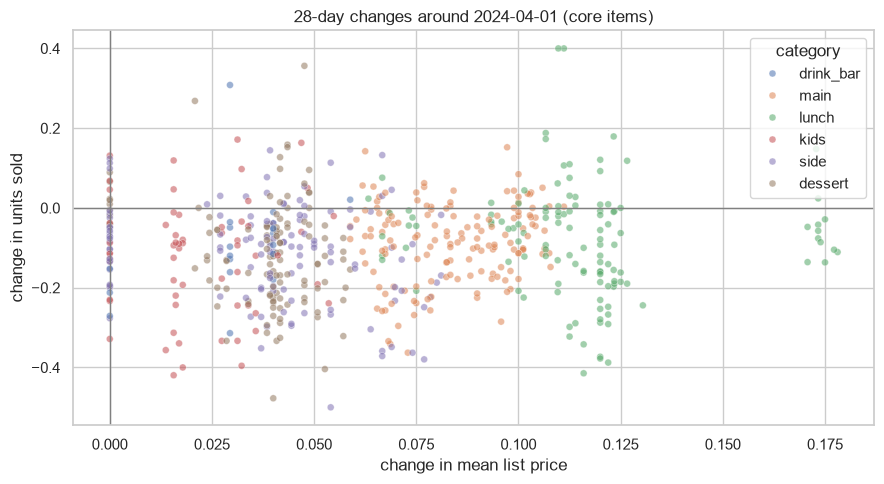

In [3]:
orders=orders.merge(menus[['item_id','category','menu_type']],on='item_id',validate='many_to_one')
core=orders[orders.menu_type.eq('core')].copy()
before=core[core.period.eq('before')].drop(columns='period');after=core[core.period.eq('after')].drop(columns=['period','category','menu_type'])
pair=before.merge(after,on=['store_id','item_id'],suffixes=('_before','_after'),validate='one_to_one')
pair['list_unit_before']=pair.list_sales_before/pair.quantity_before;pair['list_unit_after']=pair.list_sales_after/pair.quantity_after
pair['price_change']=pair.list_unit_after/pair.list_unit_before-1
pair['quantity_change']=pair.quantity_after/pair.quantity_before-1
pair['sales_change']=pair.net_after/pair.net_before-1
print('定番商品×店舗の比較可能件数:',len(pair),'うち値上げ:',int(pair.price_change.gt(1e-9).sum()),'価格据え置き:',int(pair.price_change.abs().le(1e-9).sum()),'値下げ:',int(pair.price_change.lt(-1e-9).sum()))
display(pair.groupby('category').agg(pairs=('item_id','size'),median_price_change=('price_change','median'),median_quantity_change=('quantity_change','median'),median_sales_change=('sales_change','median')))
fig,ax=plt.subplots(figsize=(9,5));sns.scatterplot(data=pair,x='price_change',y='quantity_change',hue='category',alpha=.55,s=25,ax=ax);ax.axhline(0,color='gray',lw=1);ax.axvline(0,color='gray',lw=1);ax.set(title='28-day changes around 2024-04-01 (core items)',xlabel='change in mean list price',ylabel='change in units sold');plt.tight_layout();plt.show()
print('前後差には祝日・季節・キャンペーンなどが混ざるため、価格弾力性とは解釈しない。')

## 席レイアウト変更の前後28日
2022〜2024年の両期間を完全に観測できる変更のみ。訪問者数は離脱した組を含む。席数が変わらなくても卓構成が変わることがある。

比較可能な変更件数: 9
店舗ごとの変化は時期・客層・座席構成などが異なり、改装の因果効果ではない。


,store_id,change_date,version,seats_before,seats_after,groups_before,groups_after,group_change,net_change,left_rate_before,left_rate_after,left_rate_diff
0,S001,2023-04-15,L01→L02,90,108,"7,412.0000","9,675.0000",0.3053,0.3662,0.1565,0.0719,-0.0846
2,S003,2023-05-15,L01→L02,90,90,"6,897.0000","6,633.0000",-0.0383,0.0987,0.1389,0.0865,-0.0524
5,S007,2023-07-15,L01→L02,90,90,"4,904.0000","5,412.0000",0.1036,0.1132,0.0106,0.0397,0.0291
8,S010,2023-08-15,L01→L02,90,108,"8,698.0000","9,258.0000",0.0644,0.1132,0.0845,0.0517,-0.0328
1,S002,2023-09-15,L01→L02,90,90,"7,691.0000","7,668.0000",-0.0030,0.0259,0.0615,0.0363,-0.0252
7,S009,2023-10-15,L01→L02,90,108,"3,774.0000","3,915.0000",0.0374,0.0304,0.0079,0.0059,-0.0021
3,S004,2023-11-15,L01→L02,90,108,"6,804.0000","7,471.0000",0.0980,0.1731,0.1280,0.0823,-0.0457
4,S005,2024-02-15,L01→L02,90,90,"5,501.0000","5,413.0000",-0.0160,0.0090,0.0418,0.0242,-0.0176
6,S008,2024-03-15,L01→L02,90,108,"5,959.0000","5,669.0000",-0.0487,0.0189,0.0054,0.0021,-0.0033


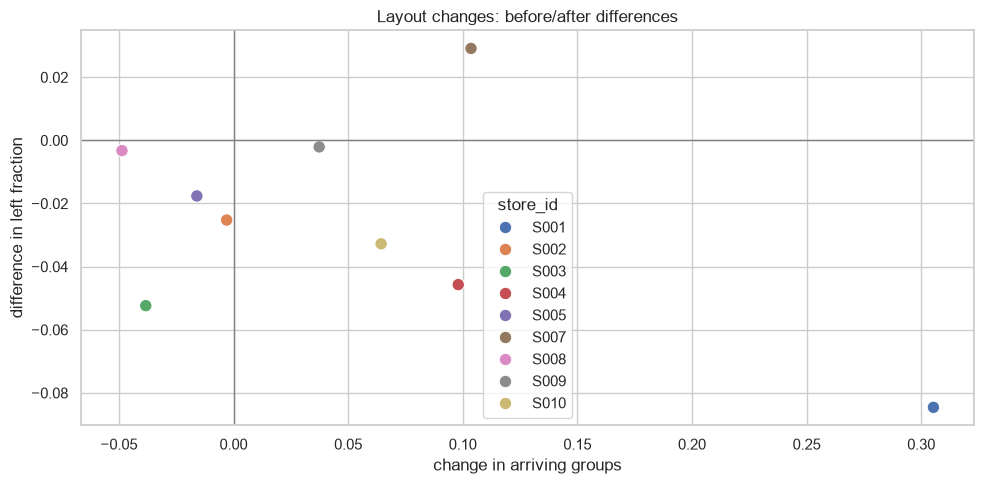

In [4]:
event_rows=[]
for e in events.itertuples(index=False):
    x=visits[(visits.store_id==e.store_id)&(visits.date>=e.date-pd.Timedelta(days=28))&(visits.date<e.date+pd.Timedelta(days=28))].copy()
    x['period']=np.where(x.date<e.date,'before','after')
    if x.groupby('period').date.nunique().to_dict()!={'after':28,'before':28}: continue
    agg=x.groupby('period')[['groups','guests','seated','left','net']].sum()
    b=agg.loc['before'];a=agg.loc['after']
    event_rows.append({'store_id':e.store_id,'change_date':e.date,'version':e.before_version+'→'+e.after_version,'seats_before':e.before_seats,'seats_after':e.after_seats,'groups_before':b.groups,'groups_after':a.groups,'group_change':a.groups/b.groups-1,'net_change':a.net/b.net-1,'left_rate_before':b.left/b.groups,'left_rate_after':a.left/a.groups,'left_rate_diff':a.left/a.groups-b.left/b.groups})
event_result=pd.DataFrame(event_rows)
display(event_result.sort_values('change_date'))
print('比較可能な変更件数:',len(event_result))
fig,ax=plt.subplots(figsize=(10,5));sns.scatterplot(data=event_result,x='group_change',y='left_rate_diff',hue='store_id',s=80,ax=ax);ax.axhline(0,color='gray',lw=1);ax.axvline(0,color='gray',lw=1);ax.set(title='Layout changes: before/after differences',xlabel='change in arriving groups',ylabel='difference in left fraction');plt.tight_layout();plt.show()
print('店舗ごとの変化は時期・客層・座席構成などが異なり、改装の因果効果ではない。')

## 解釈と次の検討
- 価格改定前後の売上額だけでなく、注文件数・数量も見る。値上げと数量変化は他要因の影響を受ける。
- 席の総数だけでなく卓構成、客層、待機・離脱の変化を確認する。
- 2025年の価格・席レイアウトは事前の予定として利用できるが、未来の来店や注文は未知。